## LAB 3

### import & default value

In [13]:
import random
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import math
from scipy.stats import norm # Used for a prediction test

In [2]:
message_lenght = 10
key_lenght = 8
forged_message_lenght = 15

## General Function

###random binary string
Used to randomly generate, key, message to better simulate the lab

In [3]:
def random_binary_string(n):
    return ''.join(random.choice('01') for _ in range(n))

# Example usage:
for i in range(0, 5):
  print(f"random string {random_binary_string(7)}")  # Output: e.g., '0101011101'

random string 1001110
random string 1111000
random string 0110101
random string 0010011
random string 1001100


In [4]:
def binary_to_decimal(binary_str):
    """Converts a binary string to a decimal integer."""
    return int(binary_str, 2)

def decimal_to_binary(n):
    """Converts a decimal integer to its binary string representation."""
    if n == 0:
        return "0"
    binary_str = ""
    while n > 0:
        binary_str = str(n % 2) + binary_str
        n = n // 2
    return binary_str

## Task 1

In [5]:
def sum_of_decimal_digits(n):
    """Returns the sum of the decimal digits of an integer."""
    return sum(int(digit) for digit in str(n))

def generate_tag(u_binary, k_binary):
    """Generates an authentication tag based on the scheme."""
    u_decimal = binary_to_decimal(u_binary)
    k_decimal = binary_to_decimal(k_binary)

    su = sum_of_decimal_digits(u_decimal)
    sk = sum_of_decimal_digits(k_decimal)

    tag = su * sk
    return tag

def verify_tag(u_binary, received_tag, k_binary):
    """Verifies whether a tag matches the message and key."""
    expected_tag = generate_tag(u_binary, k_binary)
    return expected_tag == received_tag

### testing the functionality of the mechanism

In [6]:
u = random_binary_string(message_lenght) #random string of bits
k = random_binary_string(key_lenght) #random string of bits
print(f"message {u}, key {k}")
tag = generate_tag(u, k)
print(f"decimal message representation: {binary_to_decimal(u)}")
print(f"decimal key representation: {binary_to_decimal(k)}")
print(f"Generated Tag: {tag}")
print(f"transmitted message: {u}-{decimal_to_binary(tag)}")
# Simulating verification
is_valid = verify_tag(u, tag, k)
print(f"Is the message authentic? {'Yes' if is_valid else 'No'}")

message 1101100110, key 10001100
decimal message representation: 870
decimal key representation: 140
Generated Tag: 75
transmitted message: 1101100110-1001011
Is the message authentic? Yes


## Task 2
since the tag generation is linear based on the sum of digit of the key, starting from a combination on (message, tag) it's possible to compute the sum of the digit of the in a dterministic way.

Since to generate a new tag is sufficient to know the sum of the digit of the key, and since it's possible to find it in a deterministic way with complexity O(1), P(succesful attack) = 1.

In [7]:
def key_attack(orginal_message, original_tag, forged_message = "0"):
    """Given the orginal message (u, t) it return the sum of the digit of the key
       used to generate the tag and a new tag associated with the forged message.
       Standard message is zero."""
    sk = int(tag/sum_of_decimal_digits(binary_to_decimal(orginal_message)))
    u_decimal = binary_to_decimal(forged_message)
    su = sum_of_decimal_digits(u_decimal)
    forged_tag = su * sk
    return forged_tag, sk

### Testing attack

In [8]:
    forged_u = random_binary_string(forged_message_lenght)
    print(f"Forged Message: {forged_u}")
    forged_tag, founded_sk = key_attack(u, tag, forged_u)
    print(f"Forged Tag: {forged_tag}, Finded key decimal digit sum: {founded_sk}")
    print(f"transmitted message: {forged_u}-{decimal_to_binary(forged_tag)}")
    is_valid = verify_tag(forged_u, forged_tag, k)
    print(f"Is the forged message authentic? {'Yes' if is_valid else 'No'}")

Forged Message: 100010110010100
Forged Tag: 95, Finded key decimal digit sum: 5
transmitted message: 100010110010100-1011111
Is the forged message authentic? Yes


## Task 3

used to understand the distribution of the key

In [30]:
def calculate_mean_std(freq):
  """
  Calculates the mean and standard deviation of freq.
  Args:
    freq: A Counter object where keys are values and values are probabilities.
  Returns:
    A tuple containing the mean and standard deviation.
  """
  mean = sum(k * v for k, v in freq.items())
  variance = sum((k - mean)**2 * v for k, v in freq.items())
  std_dev = math.sqrt(variance)
  return mean, std_dev

function used to deduced the distribution of the key by testing the possible combination in the given key interval

In [14]:
def compute_digit_sum_distribution(max_val):
    """Computes the distribution of digit sums for numbers up to max_val."""
    count = Counter()

    for i in range(max_val):
        s = sum_of_decimal_digits(i)
        count[s] += 1
    for digit_sum in count:
        count[digit_sum] /= max_val
    return count

def compute_possible_sum(max_val):
    """Computes the possible value of digit sums for numbers up to max_val."""
    count = compute_digit_sum_distribution(max_val)
    return list(count.keys())

def print_digit_sum_distribution(max_val):
    """Prints the distribution of digit sums for numbers up to max_val."""
    count = compute_digit_sum_distribution(max_val)
    print(f"Digit sum (range 0 to {max_val - 1}):")
    total_probability = 0
    for val in sorted(count):
        print(f"Sum {val}: {(count[val] * 100):.2f} %")
        total_probability += count[val]
    print(f"Total probability: {total_probability * 100} %")
    print(f"\nTotal different values of x: {len(count)}")

# Example usage:

print_digit_sum_distribution(2**10)

Digit sum (range 0 to 1023):
Sum 0: 0.10 %
Sum 1: 0.39 %
Sum 2: 0.78 %
Sum 3: 1.27 %
Sum 4: 1.76 %
Sum 5: 2.34 %
Sum 6: 3.03 %
Sum 7: 3.71 %
Sum 8: 4.59 %
Sum 9: 5.57 %
Sum 10: 6.35 %
Sum 11: 6.84 %
Sum 12: 7.13 %
Sum 13: 7.32 %
Sum 14: 7.32 %
Sum 15: 7.13 %
Sum 16: 6.74 %
Sum 17: 6.15 %
Sum 18: 5.37 %
Sum 19: 4.39 %
Sum 20: 3.52 %
Sum 21: 2.73 %
Sum 22: 2.05 %
Sum 23: 1.46 %
Sum 24: 0.98 %
Sum 25: 0.59 %
Sum 26: 0.29 %
Sum 27: 0.10 %
Total probability: 100.0 %

Total different values of x: 28


simple plot function to compare the obtained probabilities for the keys, wuth a normal distribution with the mean and the variance obtained by the data

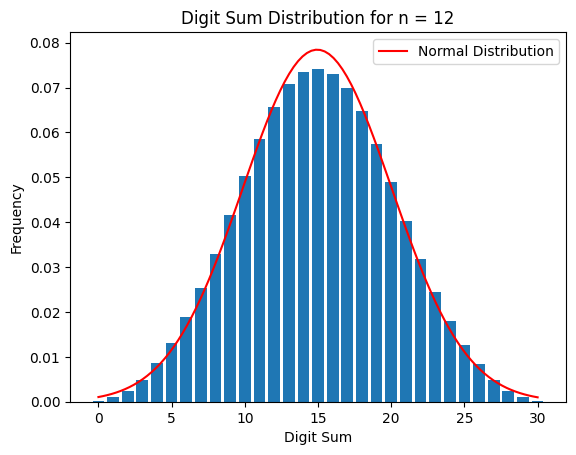

In [95]:
def plot_digit_sum_distribution(n):
    """Plots the frequency distribution of digit sums for numbers up to 2^n - 1."""
    binary_freq = compute_digit_sum_distribution(2**n)
    sums = list(binary_freq.keys())
    plt.bar(sums, binary_freq.values())
    ## adding the normal dist.
    # Calculate mean and standard deviation
    mean, std_dev = calculate_mean_std(binary_freq)

    # Generate x-values for the normal distribution curve
    x = np.linspace(min(sums), max(sums), 100)

    # Generate y-values for the normal distribution curve
    y = norm.pdf(x, mean, std_dev)

    plt.plot(x, y, 'r-', label='Normal Distribution') # Plot the normal distribution curve in red

    plt.xlabel("Digit Sum")
    plt.ylabel("Frequency")
    plt.title(f"Digit Sum Distribution for n = {n}")
    plt.legend()
    plt.show()

# Example usage
n = 12  # You can change this value
plot_digit_sum_distribution(n)

## tempting different attack

In [98]:
def simulate_attack(key_size, number_test):
  success = 0
  freq = compute_digit_sum_distribution(2**key_size)
  guessed = freq.most_common(1)[0]
  # the size of the message doesn't influnce the result
  # and i like the number 7
  u = random_binary_string(7)
  su = sum_of_decimal_digits(binary_to_decimal(u))
  for _ in range(0, number_test):
    k = random_binary_string(key_size)
    sk = sum_of_decimal_digits(binary_to_decimal(k))
    if verify_tag(u, su * guessed[0], k):
      success += 1
  return success/number_test, guessed

number_trials = 10000
success_prob, guessed_key = simulate_attack(10, number_trials)
print(f"test with {number_trials} trials")
print(f"the attack succed {(success_prob * 100):.2f}% using the key: {guessed_key[0]} with a theoretical probability of {(guessed_key[1]*100):.2f}%")

test with 10000 trials
the attack succed 7.67% using the key: 13 with a theoretical probability of 7.32%


# IMPORTANT OBSERVATION
we assumed that the key is uniformly distributed between 0-2^n but this is not true, since both the message and key can't be zero, otherwise the tag would be zero and the tag will be useless so in reality the proability distribution is alittle bit higher.

Since we suppose that the key are going to be long enought and the sum of the digit is zero only if the key is zero, then P(key = 0) = 1/|K|, assuming uniformity, so this case can be ignored for key **sufficiently large**

### Trying to find an upper bound

The idea is to compare the distribution for the interval (0, 2^n) and the interval (0, 10^m) where:

+ m = number of digit of the decima representation of 2^n

In [99]:
def binary_digits_to_decimal_digits(binary_digits: int) -> int:
    if binary_digits <= 0:
        return 0  # No digits to convert
    return math.floor(binary_digits * math.log10(2)) + 1

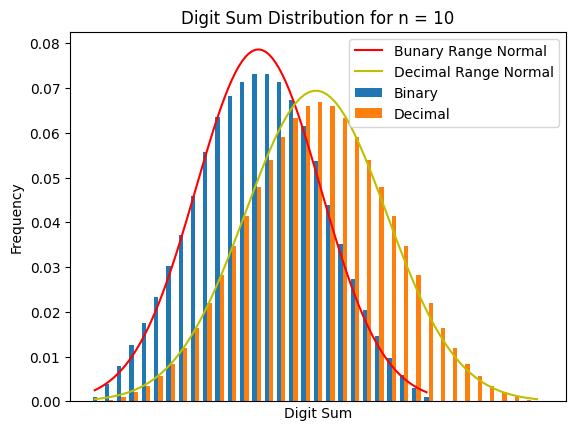

In [27]:
def plot_digit_sum_distribution(n):
    """Plots the frequency distribution of digit sums for binary and decimal numbers."""
    binary_freq = compute_digit_sum_distribution(2**n)
    decimal_freq = compute_digit_sum_distribution(10**binary_digits_to_decimal_digits(n))

    # Get unique digit sums from both distributions
    all_sums = sorted(set(list(binary_freq.keys()) + list(decimal_freq.keys())))

    # Get frequencies for each digit sum, filling with 0 if not present
    binary_values = [binary_freq.get(s, 0) for s in all_sums]
    decimal_values = [decimal_freq.get(s, 0) for s in all_sums]

    # Create bar plot with two bars for each digit sum
    width = 0.35  # Width of each bar
    x = range(len(all_sums))  # X-axis positions for bars

    plt.bar(x, binary_values, width, label='Binary')
    plt.bar([i + width for i in x], decimal_values, width, label='Decimal')
    ##---------------------------------------------
    ## adding the normal dist.
    # Calculate mean and standard deviation
    sums = list(binary_freq.keys())
    mean, std_dev = calculate_mean_std(binary_freq)

    # Generate x-values for the normal distribution curve
    x = np.linspace(min(sums), max(sums), 100)

    # Generate y-values for the normal distribution curve
    y = norm.pdf(x, mean, std_dev)

    plt.plot(x, y, 'r-', label='Bunary Range Normal') # Plot the normal distribution curve in red
    ## adding the normal dist.
    # Calculate mean and standard deviation
    sums = list(decimal_freq.keys())
    mean, std_dev = calculate_mean_std(decimal_freq)

    # Generate x-values for the normal distribution curve
    x = np.linspace(min(sums), max(sums), 100)

    # Generate y-values for the normal distribution curve
    y = norm.pdf(x, mean, std_dev)

    plt.plot(x, y, 'y-', label='Decimal Range Normal') # Plot the normal distribution curve in red
    plt.xlabel("Digit Sum")
    plt.ylabel("Frequency")
    plt.title(f"Digit Sum Distribution for n = {n}")
    plt.xticks(ticks=[])
    plt.legend()
    plt.show()

# Example usage
n = 10  # You can change this value
plot_digit_sum_distribution(n)

### trying to create a linear approximation
the idea is to find the correlation and the mean of the distribution based on the interval size (measured in number of bits),assuming that the distribution follow a normal distribution

In [88]:
def calculate_mean_std(freq):
  """Calculates mean and standard deviation from freq."""
  # (Same as before)
  mean = sum(k * v for k, v in freq.items())
  variance = sum((k - mean)**2 * v for k, v in freq.items())
  std_dev = np.sqrt(variance)
  return mean, std_dev

def predict_mean_variance(sizes, means, variances, new_size):
  """Predicts mean and variance for a new counter size."""
  # Fit a linear regression model for mean vs size
  mean_coeffs = np.polyfit(sizes, means, 1)
  predicted_mean = np.polyval(mean_coeffs, new_size)

  # Fit a linear regression model for variance vs size
  variance_coeffs = np.polyfit(sizes, variances, 1)
  predicted_variance = np.polyval(variance_coeffs, new_size)

  return predicted_mean, predicted_variance

# Example usage
sizes = [7, 10, 13, 16, 20]
counters = [compute_digit_sum_distribution(2**s) for s in sizes]  # Example counters
means = [calculate_mean_std(c)[0] for c in counters]
variances = [calculate_mean_std(c)[1]**2 for c in counters]

new_size = 22
predicted_mean, predicted_variance = predict_mean_variance(sizes, means, variances, new_size)

print(f"Predicted mean for size {new_size}: {predicted_mean}")
print(f"Predicted variance for size {new_size}: {predicted_variance}")
print(f"true mean and varinace for size {new_size}: {calculate_mean_std(compute_digit_sum_distribution(2**new_size))}")

Predicted mean for size 22: 29.29966687599509
Predicted variance for size 22: 53.18198455212822
true mean and varinace for size 22: (28.420565128326416, np.float64(7.09910241024345))


**After testing the linear interpolation** of the mean and variance we can se that, the mean it's pretty accurate, so even if the variance could be a lot better it's still possible to use this idea

In [91]:
def plot_digit_sum_distribution_predicted(n, predicted_mean, predicted_variance):
    """Plots the frequency distribution of digit sums for numbers up to 2^n - 1."""
    binary_freq = compute_digit_sum_distribution(2**n)
    sums = list(binary_freq.keys())
    plt.bar(sums, binary_freq.values())
    ## adding the normal dist.
    # Calculate mean and standard deviation
    mean, std_dev = calculate_mean_std(binary_freq)
    print(mean, std_dev)
    # Generate x-values for the normal distribution curve
    x = np.linspace(min(sums), max(sums), 100)

    # Generate y-values for the normal distribution curve
    y = norm.pdf(x, mean, std_dev)

    plt.plot(x, y, 'r-', label=f"Normal Distribution {mean:.2f}") # Plot the normal distribution curve in red
    y = norm.pdf(x, predicted_mean, predicted_variance)
    print(predicted_mean, predicted_variance)
    plt.plot(x, y, 'y-', label=f"Predicted Distribution {predicted_mean:.2f}") # Plot the normal distribution curve in red

    # Add vertical lines for means
    plt.axvline(x=mean, color='b', linestyle='--', label='Actual Mean')
    plt.axvline(x=predicted_mean, color='g', linestyle='--', label='Predicted Mean')

    plt.xlabel("Digit Sum")
    plt.ylabel("Frequency")
    plt.title(f"Digit Sum Distribution for n = {n}")
    plt.legend()
    plt.show()

In [89]:
sizes = [7, 9, 10, 11, 13, 14, 15]
counters = [compute_digit_sum_distribution(2**s) for s in sizes]  # Example counters
means = [calculate_mean_std(c)[0] for c in counters]
variances = [calculate_mean_std(c)[1]**2 for c in counters]

predicted_mean, predicted_variance = predict_mean_variance(sizes, means, variances, new_size)

28.420565128326416 7.09910241024345
28.3525478826093 48.7884297964804


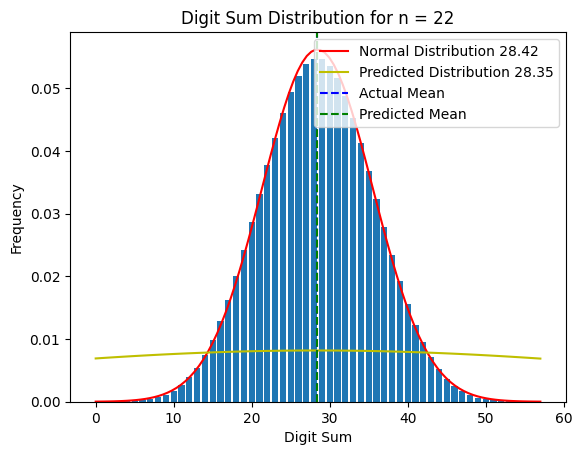

In [92]:
plot_digit_sum_distribution_predicted(new_size, predicted_mean, predicted_variance)

as we can se the distribution obtained with the linear interpolation it's completly different but the mean are pretty closed

### Testing the idea

comparing the prediction with the actual distribution calculated testing all the possible key and the predicted mean

In [93]:
def simulate_attack_with_key(guessed, key_size, number_test):
  success = 0
  guessed = int(round(guessed))
  # the size of the message doesn't influnce the result
  # and i like the number 7
  u = random_binary_string(7)
  su = sum_of_decimal_digits(binary_to_decimal(u))
  for _ in range(0, number_test):
    k = random_binary_string(key_size)
    sk = sum_of_decimal_digits(binary_to_decimal(k))
    if verify_tag(u, su * guessed, k):
      success += 1
  return success/number_test

print(f"attack performed based on key freaquence analysis: {simulate_attack(new_size, 10000)}")
print(f"attack performed based on key predicted mean analysis: {simulate_attack_with_key(predicted_mean,new_size , 10000)}")

attack performed based on key freaquence analysis: (0.0525, (28, 0.05475592613220215))
attack performed based on key predicted mean analysis: 0.0541


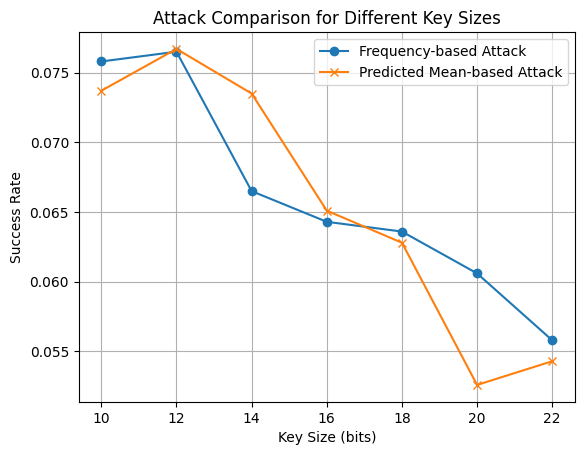

In [94]:
def plot_attack_comparison(key_sizes, num_tests=10000):
    """Plots the comparison of attack success rates for different key sizes."""
    freq_attack_results = []
    predicted_mean_attack_results = []

    # Get predicted mean and variance data
    sizes = [7, 9, 10, 11, 13, 14, 15]  # Replace with your actual sizes
    counters = [compute_digit_sum_distribution(2**s) for s in sizes]
    means = [calculate_mean_std(c)[0] for c in counters]
    variances = [calculate_mean_std(c)[1]**2 for c in counters]

    for key_size in key_sizes:
        # Frequency-based attack
        freq_attack_results.append(simulate_attack(key_size, num_tests))

        # Predicted mean-based attack
        predicted_mean, predicted_variance = predict_mean_variance(sizes, means, variances, key_size)
        predicted_mean_attack_results.append(simulate_attack_with_key(predicted_mean, key_size, num_tests))

    # Plotting
    plt.plot(key_sizes, [result[0] for result in freq_attack_results], label='Frequency-based Attack', marker='o')
    plt.plot(key_sizes, predicted_mean_attack_results, label='Predicted Mean-based Attack', marker='x')

    plt.xlabel("Key Size (bits)")
    plt.ylabel("Success Rate")
    plt.title("Attack Comparison for Different Key Sizes")
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
key_sizes_to_test = [10, 12, 14, 16, 18, 20, 22]
plot_attack_comparison(key_sizes_to_test)

# trying with a pretty large key
it would be impossible to compute the guessing prob. with a the classical sampling method

In [114]:
big_key_size = 120
predicted_mean, predicted_variance = predict_mean_variance(sizes, means, variances, big_key_size)
upper_bound = 9*binary_digits_to_decimal_digits(big_key_size)
print(f"upper bound to the possible key: {upper_bound} with a minimum prob.: {(1/upper_bound)}")
print(f"attack performed based on key predicted mean analysis: {simulate_attack_with_key(predicted_mean,big_key_size , 100000)}")

upper bound to the possible key: 333 with a minimum prob.: 0.003003003003003003
attack performed based on key predicted mean analysis: 0.02176


## Task 3 RESULT

+ (**classic idea**) we can saw from the plot that the key follow a normal distribution, and it correctly gave the guessing probability of the key for each possible one. The only problem is that to generate the key, i need to compute all of the posible key to generate the freaquency map, this implies a time equal to O(2^n), that can be alleviate by the random sampling of the key over a sufficient number of trials

+ (**upper bound**) gave a pretty result over the binary true distribution and since it's in base 10, it's possible to calculate the key and the mean in O(1) beacause I have a closed form function that gave me the number of possible key. There is also the problem correlated to the high variance based on n, since different value of n may have the same decimal digit.

+ (**predicted mean**) from the last graph we can see that more or less the predicted mean gave similar and acceptable result over the actual mean. And so we can reach a guessing probability, similar to the optimal one in O(1) time, instead of O(2^n). it's an euristic algorithm